In [1]:
'''
Santa 2026 | One Target vs. Four

A matched pilot of single-target and joint-target reconstruction
on the same verified arithmetic programs.
'''

# Santa 2026 · One Target vs. Four

**Can a short block make better use of shared intermediate values?**

| Design | Setting |
|:---|:---|
| Reference | 128,485 instructions across 1,000 puzzles |
| Sample | 30 puzzles with close targets and 30 matched controls |
| Arms | Rebuild one target or four targets at a time |
| Acceptance | A shorter program must replay exactly in 48 registers |

Both arms start from the same program for each puzzle. The main outcome is the number of instructions removed from the full portfolio after independent replay.

In [2]:
'''
Credits

Ertuğrul Özer (ozertuu) supplied the version 506 portfolio. Its Kaggle
listing reports the dataset license as Unknown.
https://www.kaggle.com/datasets/ozertuu/santa-2026-verified-programs/versions/506

Atakan Aldemir authored the C++ target-block engine (Apache 2.0).
https://www.kaggle.com/code/atakanaldemir/santa-2026-joint-recipes-for-large-puzzles

goodpjw2008 packaged the engine sources in dataset version 246.
https://www.kaggle.com/datasets/goodpjw2008/santa-2026-dag-lns-programs/versions/246

The matched sampling, paired execution, exact referee and figures are
implemented in this notebook.
'''

## 1 · Run settings and pinned inputs

In [3]:
EXPERIMENT_SLUG = '06_target_block_pilot'
ENGINE_SLUG = 'santa-2026-dag-lns-programs'
PAIRS = 30
SECONDS_PER_PUZZLE = 4.0
VARIANTS = (0, 6, 9)
WORKERS = 4

In [4]:
import csv
import hashlib
import json
from collections import Counter
from dataclasses import dataclass
from pathlib import Path
from statistics import median
from tempfile import TemporaryDirectory
from time import perf_counter


COMPETITION = 'santa-2026'
DATASET_OWNER = 'ozertuu'
DATASET_SLUG = 'santa-2026-verified-programs'
DATASET_VERSION = 506
PORTFOLIO_SHA256 = '4560d52245b3eca32f229a03a26b368c1fb506e0aa3ffa950607434e5b9bd0e7'
EXPECTED_SCORE = 128_485
SUBMISSION_COLUMNS = ['id', 'program']
MAX_INSTRUCTIONS = 4_096
MAX_PROGRAM_BYTES = 131_072

Instruction = tuple[str, int, int, int]
Program = tuple[Instruction, ...]


@dataclass(frozen=True)
class Config:
    puzzles_csv: Path
    portfolio_csv: Path
    output_csv: Path

    @classmethod
    def discover(cls) -> 'Config':
        kaggle = Path('/kaggle/input')
        if kaggle.is_dir():
            puzzles = cls.locate(kaggle, COMPETITION, 'puzzles.csv')
            programs = cls.locate(kaggle, DATASET_SLUG, 'best_programs.csv')
            return cls(puzzles, programs, Path('/kaggle/working/submission.csv'))

        root = Path.cwd()
        competition_dir = root / 'competitions' / 'public-comp' / COMPETITION
        if competition_dir.is_dir():
            root = competition_dir
        elif root.name == EXPERIMENT_SLUG and root.parent.name == COMPETITION:
            root = root.parent
        data = root / 'data'
        return cls(
            data / 'puzzles.csv',
            data / DATASET_SLUG / 'best_programs.csv',
            root / 'working' / EXPERIMENT_SLUG / 'submission.csv',
        )

    @staticmethod
    def locate(root: Path, slug: str, filename: str) -> Path:
        matches = [path for path in root.rglob(filename) if slug in path.parent.parts]
        if len(matches) != 1:
            raise FileNotFoundError(
                f'Expected one {slug}/{filename} input, found {len(matches)}'
            )
        return matches[0]

    def check_inputs(self) -> None:
        if not self.puzzles_csv.is_file():
            raise FileNotFoundError(
                f'Attach the {COMPETITION} competition data or copy puzzles.csv '
                f'to {self.puzzles_csv}'
            )
        if not self.portfolio_csv.is_file():
            raise FileNotFoundError(
                f'Attach {DATASET_OWNER}/{DATASET_SLUG} version {DATASET_VERSION} '
                f'or copy best_programs.csv to {self.portfolio_csv}'
            )
        digest = hashlib.sha256(self.portfolio_csv.read_bytes()).hexdigest()
        if digest != PORTFOLIO_SHA256:
            raise ValueError(
                f'Expected {DATASET_SLUG} version {DATASET_VERSION}. '
                f'Unexpected SHA-256 for {self.portfolio_csv}: {digest}'
            )

In [5]:
@dataclass(frozen=True)
class Puzzle:
    starts: tuple[int, ...]
    targets: frozenset[int]
    value_limit: int
    register_count: int

    @classmethod
    def from_row(cls, row: dict[str, str]) -> 'Puzzle':
        return cls(
            tuple(json.loads(row['starting_values'])),
            frozenset(json.loads(row['targets'])),
            int(row['value_limit']),
            int(row['registers']),
        )


@dataclass(frozen=True)
class ProgramProfile:
    length: int
    operations: Counter[str]
    peak_value: int
    populated_registers: int


class Calculator:
    '''Read both sources before writing and remember targets across overwrites.'''

    def replay(self, puzzle: Puzzle, program: Program) -> ProgramProfile:
        if len(program) > MAX_INSTRUCTIONS:
            raise ValueError('Program exceeds the instruction limit')

        registers = list(puzzle.starts) + [None] * (
            puzzle.register_count - len(puzzle.starts)
        )
        missing = set(puzzle.targets).difference(puzzle.starts)
        operations = Counter()
        peak_value = max(puzzle.starts, default=0)

        for number, instruction in enumerate(program, start=1):
            if len(instruction) != 4:
                raise ValueError(f'Step {number}: expected four instruction fields')
            op, left, right, dest = instruction
            if any(type(index) is not int or not 0 <= index < puzzle.register_count
                   for index in (left, right, dest)):
                raise ValueError(f'Step {number}: register index out of range')

            a, b = registers[left], registers[right]
            if a is None or b is None:
                raise ValueError(f'Step {number}: undefined source register')
            if op == '+':
                value = a + b
            elif op == '-':
                value = a - b
            elif op == '*':
                value = a * b
            elif op == '/' and a % b == 0:
                value = a // b
            else:
                raise ValueError(f'Step {number}: unsupported operation or inexact division')

            if not 1 <= value <= puzzle.value_limit:
                raise ValueError(f'Step {number}: result outside the value limit')
            registers[dest] = value
            missing.discard(value)
            operations[op] += 1
            peak_value = max(peak_value, value)

        if missing:
            raise ValueError(f'{len(missing)} missing targets')

        '''
        Defined registers stay populated after a write, so the final count
        is also the peak populated count for the program.
        '''
        return ProgramProfile(
            len(program), operations, peak_value,
            sum(value is not None for value in registers),
        )

In [6]:
class PortfolioPipeline:
    def __init__(self, config: Config):
        self.config = config
        self.calculator = Calculator()

    def load_puzzles(self) -> dict[str, Puzzle]:
        with self.config.puzzles_csv.open(encoding='utf-8-sig', newline='') as file:
            rows = list(csv.DictReader(file))
        puzzles = {row['id']: Puzzle.from_row(row) for row in rows}
        expected = {f'scored_{index:04d}' for index in range(1, 1_001)}
        if len(rows) != len(expected) or puzzles.keys() != expected:
            raise ValueError('Expected the 1,000 scored puzzle IDs exactly once')
        return puzzles

    def verify(
        self, path: Path, puzzles: dict[str, Puzzle],
    ) -> tuple[dict[str, Program], dict[str, ProgramProfile]]:
        programs, profiles = {}, {}
        with path.open(encoding='utf-8', newline='') as file:
            reader = csv.reader(file)
            if next(reader, None) != SUBMISSION_COLUMNS:
                raise ValueError(f'{path}: expected the id,program header')
            for row in reader:
                if len(row) != 2:
                    raise ValueError(f'{path}: expected two fields at line {reader.line_num}')
                puzzle_id, cell = row
                if puzzle_id not in puzzles or puzzle_id in programs:
                    raise ValueError(f'{path}: unexpected or duplicate ID {puzzle_id}')
                if len(cell.encode('utf-8')) > MAX_PROGRAM_BYTES:
                    raise ValueError(f'{puzzle_id}: program cell exceeds the byte limit')
                try:
                    payload = json.loads(cell)
                    if type(payload) is not list or any(type(step) is not list for step in payload):
                        raise ValueError('Expected a JSON array of instruction arrays')
                    program = tuple(tuple(step) for step in payload)
                    profiles[puzzle_id] = self.calculator.replay(puzzles[puzzle_id], program)
                except ValueError as error:
                    raise ValueError(f'{puzzle_id}: {error}') from error
                programs[puzzle_id] = program
        if programs.keys() != puzzles.keys():
            raise ValueError(f'{path}: portfolio is missing scored puzzle IDs')
        return programs, profiles

    def export(self, programs: dict[str, Program], puzzles: dict[str, Puzzle]) -> None:
        output = self.config.output_csv
        output.parent.mkdir(parents=True, exist_ok=True)
        with TemporaryDirectory(dir=output.parent) as directory:
            temporary = Path(directory) / output.name
            with temporary.open('w', encoding='utf-8', newline='') as file:
                writer = csv.writer(file)
                writer.writerow(SUBMISSION_COLUMNS)
                for puzzle_id in sorted(programs):
                    cell = json.dumps(programs[puzzle_id], separators=(',', ':'))
                    writer.writerow((puzzle_id, cell))
            written, _ = self.verify(temporary, puzzles)
            if written != programs:
                raise RuntimeError('The exported programs differ from the verified input')
            temporary.replace(output)

## 2 · What the engine is testing

The engine cuts dependency regions that can be rebuilt while keeping their outputs available to the remaining program. The four-target arm can propose arithmetic recipes that share work across several targets. The unchanged upstream engine attempts to place completed candidate graphs in registers. This compares block sizes under the same search settings and wall-clock cap. Register allocation takes place after candidate generation in this pilot.

The sample is restricted to 25–32 targets. The high-structure cohort is a proxy based on close pairs of adjacent sorted targets. Controls come from the lower half of that proxy and are matched to the clustered group by baseline instruction count, then target count.

In [7]:
from concurrent.futures import ThreadPoolExecutor
from shutil import which
from subprocess import CalledProcessError, TimeoutExpired, run


@dataclass(frozen=True)
class Trial:
    puzzle_id: str
    group: int
    program: Program
    elapsed: float
    completed: int
    timed_out: int


class TargetBlockPilot:
    def __init__(self, portfolio: PortfolioPipeline):
        self.portfolio = portfolio

    @staticmethod
    def clustering(puzzle: Puzzle) -> float:
        targets = sorted(puzzle.targets)
        return sum(
            (b - a) * 512 <= a for a, b in zip(targets, targets[1:])
        ) / (len(targets) - 1)

    def sample(self, puzzles, baseline):
        eligible = [pid for pid in puzzles if 25 <= len(puzzles[pid].targets) <= 32]
        rates = {pid: self.clustering(puzzles[pid]) for pid in eligible}
        ranked = sorted(eligible, key=lambda pid: (-rates[pid], -len(baseline[pid]), pid))
        structured = ranked[:PAIRS]
        low_structure = set(ranked[len(ranked)//2:])
        controls = []
        for pid in structured:
            control = min(low_structure, key=lambda alt: (
                abs(len(baseline[pid]) - len(baseline[alt])),
                abs(len(puzzles[pid].targets) - len(puzzles[alt].targets)), alt,
            ))
            controls.append(control)
            low_structure.remove(control)
        return structured, controls

    @staticmethod
    def source_path(config: Config) -> Path:
        kaggle = Path('/kaggle/input')
        if kaggle.is_dir():
            source = config.locate(kaggle, ENGINE_SLUG, 'elf_target_blocks.cpp')
        else:
            source = config.puzzles_csv.parent / ENGINE_SLUG / 'atakan_optimizers' / 'elf_target_blocks.cpp'
        if not source.is_file():
            raise FileNotFoundError(f'Expected the pinned target-block engine at {source}')
        return source

    @staticmethod
    def compile(source: Path, output: Path) -> None:
        compiler = which('g++-15') or which('g++')
        if compiler is None:
            raise FileNotFoundError('A GNU C++17 compiler is required to build the target-block engine')
        try:
            run([compiler, '-O3', '-std=c++17', str(source), '-o', str(output)],
                capture_output=True, text=True, check=True)
        except CalledProcessError as error:
            raise RuntimeError(f'Could not compile {source.name}\n{error.stderr}') from error

    @staticmethod
    def encode(pid: str, puzzle: Puzzle, program: Program) -> str:
        rows = [
            f'{pid} {puzzle.value_limit} {len(puzzle.starts)} {len(puzzle.targets)} {len(program)}',
            ' '.join(map(str, puzzle.starts)), ' '.join(map(str, sorted(puzzle.targets))),
            *(' '.join(map(str, instruction)) for instruction in program),
        ]
        return '\n'.join(rows) + '\n'

    @staticmethod
    def decode(pid: str, output: str) -> Program:
        header, *rows = output.splitlines()
        output_id, size, _ = header.split()
        if output_id != pid or len(rows) != int(size):
            raise ValueError(f'{pid}: invalid target-block output')
        return tuple((op, int(a), int(b), int(dest)) for op,a,b,dest in map(str.split, rows))

    def trial(self, binary: Path, pid: str, puzzle: Puzzle, baseline: Program, group: int) -> Trial:
        best = baseline
        start = perf_counter()
        timed_out = completed = 0
        for variant in VARIANTS:
            remaining = SECONDS_PER_PUZZLE - (perf_counter() - start)
            if remaining <= 0:
                break
            command = [str(binary), str(group), '8', '8', '5', '72', str(variant)]
            try:
                response = run(command, input=self.encode(pid, puzzle, best), check=True,
                               capture_output=True, text=True, timeout=remaining)
            except TimeoutExpired:
                timed_out += 1
                break
            except CalledProcessError as error:
                raise RuntimeError(f'{pid}, group {group}: {error.stderr}') from error
            completed += 1
            candidate = self.decode(pid, response.stdout)
            self.portfolio.calculator.replay(puzzle, candidate)
            if len(candidate) < len(best):
                best = candidate
        return Trial(pid, group, best, perf_counter() - start, completed, timed_out)

    def run(self):
        config = self.portfolio.config
        config.check_inputs()
        puzzles = self.portfolio.load_puzzles()
        baseline, _ = self.portfolio.verify(config.portfolio_csv, puzzles)
        if sum(map(len, baseline.values())) != EXPECTED_SCORE:
            raise ValueError('Unexpected baseline score')
        structured, controls = self.sample(puzzles, baseline)
        selected = [pid for pair in zip(structured, controls) for pid in pair]

        def compare(item):
            index, pid = item
            modes = (1, 4) if index % 4 in (0, 1) else (4, 1)
            return [self.trial(binary, pid, puzzles[pid], baseline[pid], group) for group in modes]

        with TemporaryDirectory() as directory:
            binary = Path(directory) / 'target-blocks'
            self.compile(self.source_path(config), binary)
            with ThreadPoolExecutor(max_workers=WORKERS) as workers:
                trials = [trial for pair in workers.map(compare, enumerate(selected)) for trial in pair]
        return puzzles, baseline, structured, controls, trials

## 3 · Results and figures

In the table, completed trials are native process runs that returned before their cap. The runtime plot shows actual wall time. The savings plot counts only shorter tapes that passed our exact referee. The notebook writes the best of the two arms only if at least one puzzle improves.

In [8]:
import matplotlib as mpl
import matplotlib.pyplot as plt


class BlockReport:
    @staticmethod
    def render(puzzles, baseline, structured, controls, trials, portfolio, started):
        original = sum(map(len, baseline.values()))
        subsets = {'Clustered': structured, 'Matched controls': controls}
        trial_map = {(item.puzzle_id, item.group): item for item in trials}
        methods = {1: 'One target', 4: 'Four targets'}
        totals = Counter()
        wins = Counter()
        medians = {}
        stages = []
        print(f'Pinned baseline: {original:,} | Puzzles per arm: {len(structured)+len(controls)}')
        print('Cohort           Mode           Saved    Improved   Median s   Completed')
        for label, pids in subsets.items():
            for group in methods:
                items = [trial_map[pid, group] for pid in pids]
                effects = [len(baseline[t.puzzle_id])-len(t.program) for t in items]
                savings = sum(effects)
                count = sum(e > 0 for e in effects)
                med = median(t.elapsed for t in items)
                completed = sum(t.completed for t in items)
                totals[group] += savings
                wins[group] += count
                medians[label, group] = med
                stages.append((label, group, savings))
                print(f'{label:16} {methods[group]:13} {savings:5} {count:11} '
                      f'{med:10.2f} {completed:5}/{len(items)*len(VARIANTS):<4}')
        for group in methods:
            print(f'{methods[group]} portfolio: {original-totals[group]:,} | '
                  f'timeouts: {sum(t.timed_out for t in trials if t.group == group)}')

        winners = baseline.copy()
        changes = []
        for pid in structured + controls:
            t = min((trial_map[pid, g] for g in methods), key=lambda row: len(row.program))
            if len(t.program) < len(baseline[pid]):
                winners[pid] = t.program
                changes.append((pid, len(baseline[pid]), len(t.program), methods[t.group]))
        print(f'Best of both: {sum(map(len, winners.values())):,} | '
              f'{len(changes):,} puzzles improved | {perf_counter()-started:.1f}s')
        for pid, before, after, method in changes:
            print(f'{pid}: {before} → {after} ({method})')
        if changes:
            portfolio.export(winners, puzzles)
            print(f'Verified CSV: {portfolio.config.output_csv}')
        else:
            print('This run exported no CSV because the verified score did not improve.')

        BlockReport.figures(puzzles, baseline, subsets, medians, stages)

    @staticmethod
    def figures(puzzles, baseline, subsets, medians, stages):
        orange, blue, gray = '#d9480f', '#1c7ed6', '#495057'
        mpl.rcParams.update({
            'figure.facecolor': 'white', 'axes.facecolor': 'white',
            'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#dee2e6',
            'axes.titlelocation': 'left', 'axes.titleweight': 'bold',
            'axes.labelcolor': gray, 'grid.color': '#e9ecef', 'legend.frameon': False,
            'text.color': '#212529', 'figure.dpi': 120,
        })
        figure, (left, right) = plt.subplots(1, 2, figsize=(10.4, 3.65), layout='constrained')
        colors = {'Clustered': orange, 'Matched controls': blue}
        for name, ids in reversed(list(subsets.items())):
            left.scatter([len(baseline[pid]) for pid in ids],
                         [100*TargetBlockPilot.clustering(puzzles[pid]) for pid in ids],
                         color=colors[name], alpha=.75, s=30, label=name)
        left.set_title('Matched cost, different target spacing', pad=10)
        left.set_xlabel('Baseline instructions per puzzle')
        left.set_ylabel('Adjacent target pairs within 1/512 (%)')
        left.grid(axis='y')
        left.set_axisbelow(True)
        left.legend(loc='best', fontsize=8)

        for index, name in enumerate(subsets):
            for group, shift, color in ((1, -.19, blue), (4, .19, orange)):
                value = medians[name, group]
                bar = right.bar(index+shift, value, width=.32, color=color,
                                label=f'{group} target' + ('s' if group > 1 else '') if index == 0 else None)
                right.bar_label(bar, labels=[f'{value:.2f}s'], padding=4, fontsize=9)
        right.set_xticks(range(len(subsets)), list(subsets))
        right.set_ylim(0, max(medians.values())*1.24)
        right.set_title('Median search time per puzzle', pad=10)
        right.set_ylabel('Wall time (seconds)')
        right.grid(axis='y')
        right.set_axisbelow(True)
        right.legend(fontsize=8)
        plt.show()

        figure, ax = plt.subplots(figsize=(8.5, 2.7), layout='constrained')
        labels = [f'{cohort} · {group} target' + ('s' if group > 1 else '') for cohort, group, _ in stages]
        values = [saved for _, _, saved in stages]
        positions = list(range(len(stages)))
        ax.hlines(positions, 0, values, color=[blue, orange]*2, linewidth=3)
        ax.scatter(values, positions, color=[blue, orange]*2, s=38, zorder=3)
        for index, value in enumerate(values):
            ax.annotate(str(value), (value, index), xytext=(8, 0), textcoords='offset points', va='center')
        ax.set_yticks(positions, labels)
        ax.invert_yaxis()
        ax.set_xlim(-.12, max(1, max(values))*1.24)
        ax.set_title('Instruction savings after exact replay', pad=10)
        ax.set_xlabel('Instructions removed from the pinned portfolio')
        ax.grid(axis='x')
        plt.show()

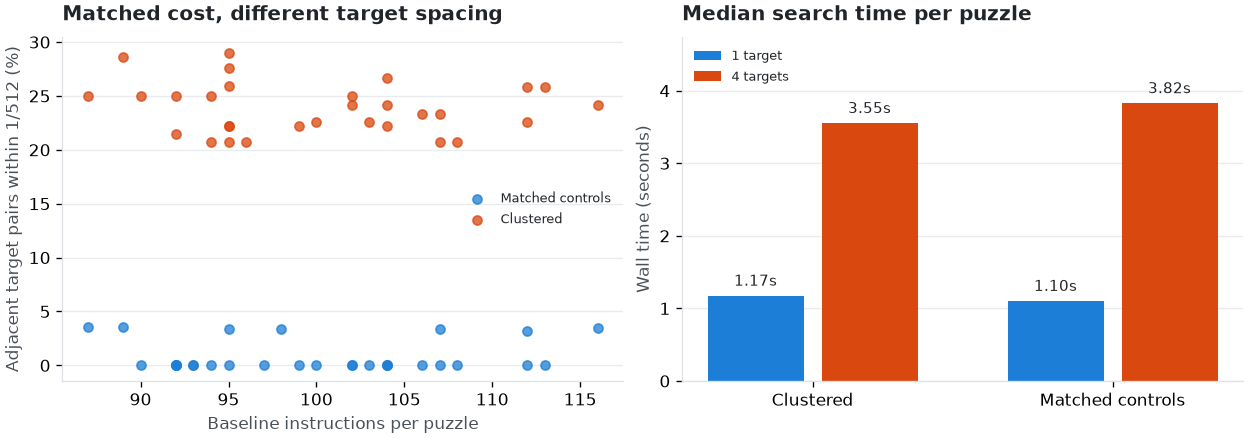

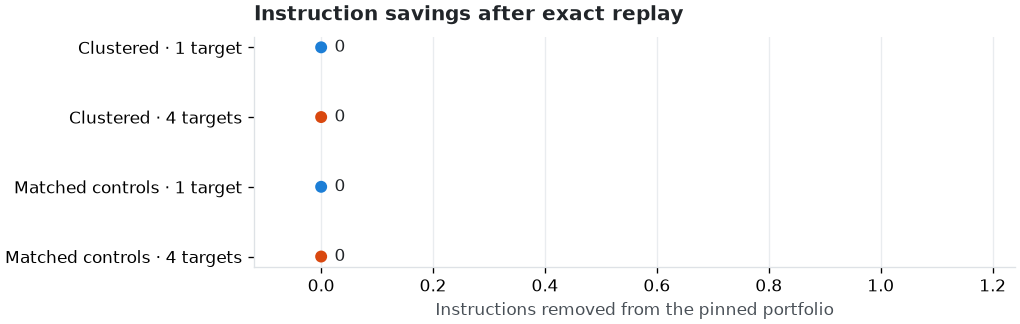

Pinned baseline: 128,485 | Puzzles per arm: 60
Cohort           Mode           Saved    Improved   Median s   Completed
Clustered        One target        0           0       1.17    90/90  
Clustered        Four targets      0           0       3.55    86/90  
Matched controls One target        0           0       1.10    90/90  
Matched controls Four targets      0           0       3.82    82/90  
One target portfolio: 128,485 | timeouts: 0
Four targets portfolio: 128,485 | timeouts: 12
Best of both: 128,485 | 0 puzzles improved | 77.5s
This run exported no CSV because the verified score did not improve.


In [9]:
example = 'sample 2 1\n+ 0 0 1\n* 1 0 2\n'
assert TargetBlockPilot.decode('sample', example) == (('+', 0, 0, 1), ('*', 1, 0, 2))

started = perf_counter()
portfolio = PortfolioPipeline(Config.discover())
puzzles, baseline, structured, controls, trials = TargetBlockPilot(portfolio).run()
assert len({(row.puzzle_id, row.group) for row in trials}) == 4 * PAIRS
BlockReport.render(puzzles, baseline, structured, controls, trials, portfolio, started)

## 4 · What this run established

In this local run, both arms scored **128,485**. Four-target reconstruction used about three times as much median wall time per puzzle and hit the cap on **12 of 60** puzzles. The single-target arm completed all 180 configured variants.

These measurements apply to the tested engine, sample, and four-second budget. The engine checked register capacity after proposing each rewrite. A search that uses lifetimes while choosing arithmetic recipes remains a separate hypothesis.